# Solution: Mission 02 — Weather-Aware Demand Pipeline

This notebook is one possible solution. Try the mission yourself before you read it.

In [1]:
import contextlib
import io
import json
import shutil
import sys
import tempfile
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets

WORK = Path(tempfile.mkdtemp())

import urllib.parse
import urllib.request
import warnings

warnings.filterwarnings("ignore")
import dagster as dg
import dlt

@contextlib.contextmanager
def quiet():
    with contextlib.redirect_stderr(io.StringIO()):
        yield

## Task 1: Ingest with dlt (merge, re-run)

In [2]:
DB = str(WORK / "demand_weather.duckdb")

@dlt.resource(name="weather_hourly", write_disposition="merge", primary_key="observed_at")
def weather(start="2024-01-01", end="2024-02-29"):
    params = {"latitude": 40.71, "longitude": -74.01, "start_date": start, "end_date": end, "timezone": "America/New_York",
              "hourly": "temperature_2m,precipitation,snowfall"}
    with urllib.request.urlopen("https://archive-api.open-meteo.com/v1/archive?" + urllib.parse.urlencode(params), timeout=60) as r:
        h = json.load(r)["hourly"]
    for i, ts in enumerate(h["time"]):
        yield {"observed_at": ts, "temperature_2m": h["temperature_2m"][i], "precipitation": h["precipitation"][i],
               "snowfall": h["snowfall"][i]}

pipe = dlt.pipeline(pipeline_name="weather", destination=dlt.destinations.duckdb(DB), dataset_name="raw",
                    pipelines_dir=str(WORK / "dlt"))
for _ in range(2):
    pipe.run(weather())
con = duckdb.connect(DB)
con.execute("SET TimeZone = 'UTC'")              # timestamps were loaded as New York local time
n, distinct = con.sql("select count(*), count(distinct observed_at) from raw.weather_hourly").fetchone()
con.close()
print(f"after two runs: {n} rows, {distinct} distinct hours -> duplicates: {n - distinct}")

after two runs: 1440 rows, 1440 distinct hours -> duplicates: 0


## Tasks 2–3: Dagster Assets and Checks

In [3]:
@dg.asset
def daily_weather() -> pd.DataFrame:
    con = duckdb.connect(DB)
    con.execute("SET TimeZone = 'UTC'")
    df = con.sql("""select cast(observed_at as timestamp)::date as day, avg(temperature_2m) as temp_c,
                           sum(precipitation) as precip_mm, sum(snowfall) as snow_cm
                    from raw.weather_hourly group by 1 order by 1""").df()
    con.close()
    return df

@dg.asset
def daily_demand() -> pd.DataFrame:
    files = [str(datasets.taxi(m)) for m in ["2024-01", "2024-02"]]
    return duckdb.sql(f"""select cast(tpep_pickup_datetime as date) as day, count(*) as trips
                          from read_parquet({files})
                          where tpep_pickup_datetime >= '2024-01-01' and tpep_pickup_datetime < '2024-03-01'
                            and fare_amount between 3 and 500 group by 1 order by 1""").df()

@dg.asset
def demand_weather(context: dg.AssetExecutionContext, daily_weather: pd.DataFrame, daily_demand: pd.DataFrame) -> pd.DataFrame:
    out = daily_demand.merge(daily_weather, on="day", how="outer").sort_values("day")
    context.add_output_metadata({"rows": len(out), "first_day": str(out["day"].min()), "last_day": str(out["day"].max())})
    return out

@dg.asset_check(asset=demand_weather)
def sixty_days(demand_weather: pd.DataFrame) -> dg.AssetCheckResult:
    return dg.AssetCheckResult(passed=bool(len(demand_weather) == 60 and demand_weather["day"].is_unique),
                               metadata={"rows": len(demand_weather)})

@dg.asset_check(asset=demand_weather)
def valid_values(demand_weather: pd.DataFrame) -> dg.AssetCheckResult:
    ok = bool((demand_weather["snow_cm"] >= 0).all() and demand_weather["trips"].notna().all())
    return dg.AssetCheckResult(passed=ok)

with quiet():
    result = dg.materialize([daily_weather, daily_demand, demand_weather, sixty_days, valid_values])
print("materialised:", result.success)
for c in result.get_asset_check_evaluations():
    print(f"  check {c.check_name}: {'passed' if c.passed else 'FAILED'}")
dw = result.output_for_node("demand_weather")
dw.head()

materialised: True
  check sixty_days: passed
  check valid_values: passed


,day,trips,temp_c,precip_mm,snow_cm
0,2024-01-01,79573,3.454167,0.0,0.0
1,2024-01-02,74380,-0.033333,0.0,0.0
2,2024-01-03,81257,1.487500,0.0,0.0
3,2024-01-04,101558,1.862500,0.0,0.0
4,2024-01-05,101797,-1.812500,0.0,0.0


## Task 4: Demand on Snowy and Rainy Days vs Dry Days of the Same Weekday

       day   weekday       kind  snow_cm  precip_mm  trips  vs_dry_same_weekday_%
2024-01-06  Saturday       snow      5.3       11.8  95748                  -12.3
2024-01-09   Tuesday heavy rain      0.0       38.0  92714                   -6.6
2024-01-10 Wednesday heavy rain      0.0       21.7  93923                   -8.1
2024-01-13  Saturday heavy rain      0.0       19.7 103355                   -5.3
2024-01-16   Tuesday       snow      3.5        9.2  91920                   -7.4
2024-01-19    Friday       snow      1.9        2.7  94667                   -9.0
2024-01-28    Sunday heavy rain      0.0       21.3  91316                   -0.8
2024-02-13   Tuesday       snow     19.1       27.7  68054                  -31.5
2024-02-17  Saturday       snow      4.0        5.8 103798                   -4.9
2024-02-26    Monday       snow      1.7        2.9  84983                    4.3
2024-02-28 Wednesday heavy rain      0.0       15.6 110738                    8.3

median change v

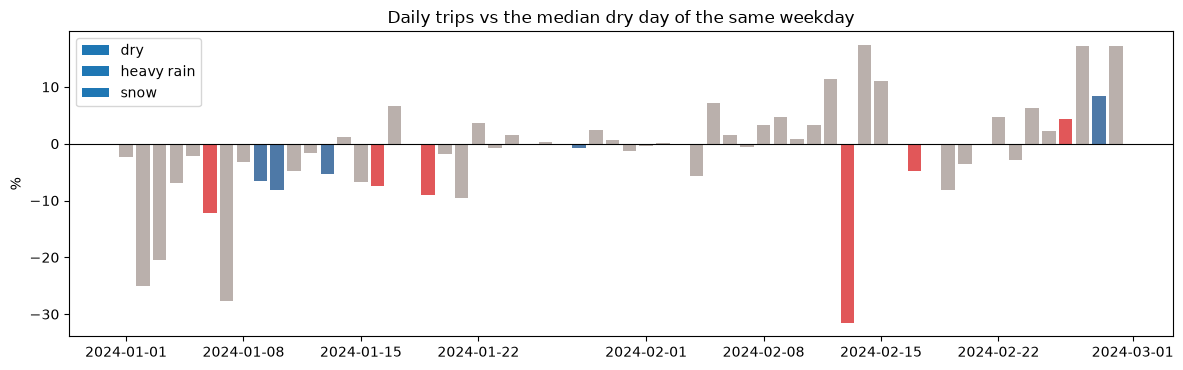

In [4]:
dw["day"] = pd.to_datetime(dw["day"])
dw["weekday"] = dw["day"].dt.day_name()
dw["kind"] = "dry"
dw.loc[dw["precip_mm"] > 10, "kind"] = "heavy rain"
dw.loc[dw["snow_cm"] > 1, "kind"] = "snow"
dry_median = dw[dw["kind"] == "dry"].groupby("weekday")["trips"].median()
dw["vs_dry_same_weekday_%"] = 100 * (dw["trips"] / dw["weekday"].map(dry_median) - 1)
wet = dw[dw["kind"] != "dry"][["day", "weekday", "kind", "snow_cm", "precip_mm", "trips", "vs_dry_same_weekday_%"]].round(1)
print(wet.to_string(index=False))
print("\nmedian change vs dry days of the same weekday:", wet.groupby("kind")["vs_dry_same_weekday_%"].median().round(1).to_dict())

fig, ax = plt.subplots(figsize=(12, 3.8))
colors = {"dry": "#BAB0AC", "heavy rain": "#4E79A7", "snow": "#E15759"}
ax.bar(dw["day"], dw["vs_dry_same_weekday_%"], color=dw["kind"].map(colors))
for k, c in colors.items():
    ax.bar([], [], color=c, label=k)
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Daily trips vs the median dry day of the same weekday", ylabel="%")
ax.legend()
plt.tight_layout()
plt.show()

## Task 5: Explanation

In [5]:
med = wet.groupby("kind")["vs_dry_same_weekday_%"].median()
n = wet["kind"].value_counts()
print(f"1. The pipeline joins daily taxi demand with Open-Meteo weather for all 60 days of January-February 2024; checks confirm complete days.")
for k in med.index:
    print(f"2. On {k} days ({n[k]} days), demand was {med[k]:+.0f} % compared with dry days of the same weekday (median).")
worst = dw.loc[dw["vs_dry_same_weekday_%"].idxmin()]
print(f"3. The largest drop was on {worst['day']:%a %d %b} ({worst['vs_dry_same_weekday_%']:+.0f} %, {worst['kind']}, "
      f"{worst['snow_cm']:.1f} cm snow, {worst['precip_mm']:.1f} mm precipitation).")
print("4. With only two months of data, these numbers are indicative, not reliable effects: holidays and events also move demand.")
print("5. Next step: add a year of history and the weather forecast as a feature in the demand model (M10 L12, M17).")

1. The pipeline joins daily taxi demand with Open-Meteo weather for all 60 days of January-February 2024; checks confirm complete days.
2. On heavy rain days (5 days), demand was -5 % compared with dry days of the same weekday (median).
2. On snow days (6 days), demand was -8 % compared with dry days of the same weekday (median).
3. The largest drop was on Tue 13 Feb (-31 %, snow, 19.1 cm snow, 27.7 mm precipitation).
4. With only two months of data, these numbers are indicative, not reliable effects: holidays and events also move demand.
5. Next step: add a year of history and the weather forecast as a feature in the demand model (M10 L12, M17).
